# Section 4: Final Model Diagnostics and Robustness

The diagnostics assess Model 3 on 4,016 parking spaces, retaining its seven predictors and the full-sample OLS specification as the primary model. Residual and influence diagnostics, a 1,000-replication bootstrap, and five-fold cross-validation evaluate model assumptions, coefficient sensitivity, and predictive accuracy. Robustness comparisons are interpreted alongside limitations arising from shared tract characteristics, data timing, and demand-responsive pricing.


**Model and sample**


The analysis examines residuals, variance and functional form, followed by coefficient-specific influence, resampling uncertainty, and held-out prediction accuracy. The diagnostic methods include residual and leverage plots, variance tests, RESET, coefficient-specific influence measures, HC1 standard errors, and bootstrap resampling.


The sample retains FLAT and TOD meters with complete observations for the common comparison-variable list. Income is included only in the sample restriction, not as a predictor in any of the three models. The source-row index is preserved so diagnostics can be linked to SpaceID and BlockFace.


In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import statsmodels.api as sm
from statsmodels.stats.stattools import jarque_bera
from statsmodels.stats.diagnostic import het_breuschpagan, het_white, linear_reset

%matplotlib inline

parking = pd.read_csv(
    "../data/processed/parking_cross_section.csv",
    dtype={"SpaceID": str, "GEOID": str}
)
print("Original observations:", len(parking))

parking = parking[parking["RateType"].isin(["FLAT", "TOD"])].copy()
parking["RateType_TOD"] = (parking["RateType"] == "TOD").astype(int)
print("FLAT + TOD observations:", len(parking))

Original observations: 4139
FLAT + TOD observations: 4060


In [2]:
variables = [
    "occupancy_rate", "price_midpoint", "time_limit_hours",
    "population_density", "nearby_restaurant_retail_count",
    "drive_alone_share", "transit_share", "RateType_TOD", "median_income"
]
print("Missing values before the common-sample restriction:")
print(parking[variables].isnull().sum())

data = parking[variables].dropna().copy()
y = data["occupancy_rate"]
print("Comparison observations:", len(data))
print("Unique SpaceIDs:", parking.loc[data.index, "SpaceID"].nunique())
print("Duplicate SpaceIDs:", parking.loc[data.index, "SpaceID"].duplicated().sum())
print("Census tracts:", parking.loc[data.index, "GEOID"].nunique())

Missing values before the common-sample restriction:
occupancy_rate                     0
price_midpoint                     0
time_limit_hours                   0
population_density                 0
nearby_restaurant_retail_count     0
drive_alone_share                  0
transit_share                      0
RateType_TOD                       0
median_income                     44
dtype: int64
Comparison observations: 4016
Unique SpaceIDs: 4016
Duplicate SpaceIDs: 0
Census tracts: 45


In [3]:
X1 = sm.add_constant(data[["price_midpoint"]])
model1 = sm.OLS(y, X1).fit()

X2 = sm.add_constant(data[[
    "price_midpoint", "population_density",
    "nearby_restaurant_retail_count"
]])
model2 = sm.OLS(y, X2).fit()

In [4]:
predictors = [
    "price_midpoint", "time_limit_hours", "population_density",
    "nearby_restaurant_retail_count", "drive_alone_share",
    "transit_share", "RateType_TOD"
]
X3 = sm.add_constant(data[predictors])
model3 = sm.OLS(y, X3).fit()

model_check = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "N": [int(model1.nobs), int(model2.nobs), int(model3.nobs)],
    "Adjusted R2": [model1.rsquared_adj, model2.rsquared_adj, model3.rsquared_adj],
    "AIC": [model1.aic, model2.aic, model3.aic],
    "BIC": [model1.bic, model2.bic, model3.bic]
})
model_check.round(5)

,Model,N,Adjusted R2,AIC,BIC
0,Model 1,4016,0.15657,-2483.67051,-2471.07443
1,Model 2,4016,0.24293,-2915.51726,-2890.32509
2,Model 3,4016,0.27235,-3070.71241,-3020.32808


In [5]:
coefficient_check = pd.DataFrame({
    "Model 1": model1.params,
    "Model 2": model2.params,
    "Model 3": model3.params
})
coefficient_check.style.format("{:.6g}", na_rep="—")

,Model 1,Model 2,Model 3
RateType_TOD,—,—,0.0330042
const,0.42375,0.392626,0.456337
drive_alone_share,—,—,-0.198101
nearby_restaurant_retail_count,—,-0.000228152,-0.000321282
population_density,—,4.05622e-06,4.57052e-06
price_midpoint,0.0545148,0.0599909,0.0556328
time_limit_hours,—,—,0.00487929
transit_share,—,—,0.0196471


All three models use 4,016 unique parking spaces in 45 Census tracts. Their adjusted R² values are 0.15657, 0.24293, and 0.27235; AIC values are −2,483.67, −2,915.52, and −3,070.71. Model 3 is the preferred specification on fit and validation criteria, so the detailed diagnostics focus on that model.


## 4(a) Linearity


### Inspect the residual plots

Fitted occupancy, residuals, and internally standardized residuals are calculated from Model 3. Residuals are plotted against fitted occupancy, price, and population density to assess changing spread or systematic patterns. The histogram gives a first view of the residual distribution without deleting unusual observations.

In [6]:
fitted = model3.fittedvalues
residuals = model3.resid
influence = model3.get_influence()
standardized = influence.resid_studentized_internal

print("Fitted occupancy outside [0, 1]:", (~fitted.between(0, 1)).sum())
residuals.describe()

Fitted occupancy outside [0, 1]: 4


count    4.016000e+03
mean    -3.244116e-13
std      1.647846e-01
min     -6.240984e-01
25%     -1.125996e-01
50%     -6.126102e-04
75%      1.102839e-01
max      5.685229e-01
dtype: float64

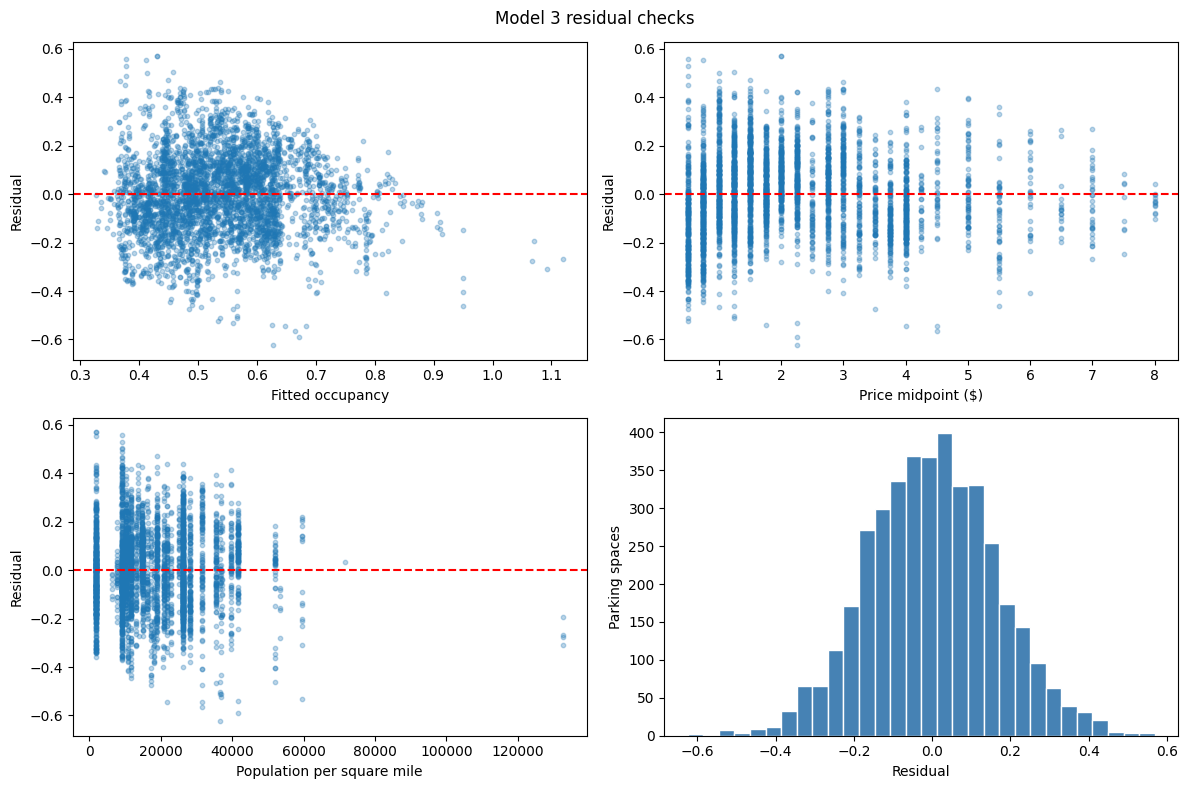

In [7]:
fig, axes = plt.subplots(2, 2, figsize=(12, 8))
axes[0, 0].scatter(fitted, residuals, s=10, alpha=0.3)
axes[0, 0].set_xlabel("Fitted occupancy")
axes[0, 1].scatter(data["price_midpoint"], residuals, s=10, alpha=0.3)
axes[0, 1].set_xlabel("Price midpoint ($)")
axes[1, 0].scatter(data["population_density"], residuals, s=10, alpha=0.3)
axes[1, 0].set_xlabel("Population per square mile")

axes[0, 0].axhline(0, color="red", linestyle="--")
axes[0, 1].axhline(0, color="red", linestyle="--")
axes[1, 0].axhline(0, color="red", linestyle="--")
axes[0, 0].set_ylabel("Residual")
axes[0, 1].set_ylabel("Residual")
axes[1, 0].set_ylabel("Residual")
axes[1, 1].hist(residuals, bins=30, color="steelblue", edgecolor="white")
axes[1, 1].set_xlabel("Residual")
axes[1, 1].set_ylabel("Parking spaces")
fig.suptitle("Model 3 residual checks")
fig.tight_layout()
plt.show()

Residuals are centered near zero overall but range from about −0.624 to 0.569. The spread is not uniform across fitted values, and shared tract measurements create vertical bands in the density plot. Four fitted values exceed one, which is another limitation of using an unconstrained linear model for a bounded outcome. These plots motivate the formal tests below; predictions are not clipped and the model remains unchanged.

### Check the linear functional form

The specification check uses the Ramsey RESET approach, adding the square of fitted values in an auxiliary test. The null is that this added term is unnecessary. A rejection points to a possible specification problem, not to the particular variable or transformation that would fix it.

In [11]:
reset = linear_reset(model3, power=2, test_type="fitted", use_f=True)
print(reset)

<F test: F=122.0777512836214, p=5.604940901584903e-28, df_denom=4.01e+03, df_num=1>


RESET gives **F = 122.078** and **p = 5.60 × 10⁻²⁸**, suggesting a problem with the current linear specification. Because this is the conventional test and heteroskedasticity is present, the result is interpreted alongside the plots rather than treated as an isolated diagnosis. The right-tailed, strictly positive density variable motivates the linear-log alternative below. The original specification remains primary.

## 4(b) Homoskedasticity


### Check constant variance and compare robust uncertainty

The variance diagnostics use the scale-location plot, Breusch–Pagan test, and White test. Both tests have a null of constant error variance; their LM and F versions are reported without treating them as separate independent checks. The scale-location plot uses the square root of absolute internally standardized residuals.

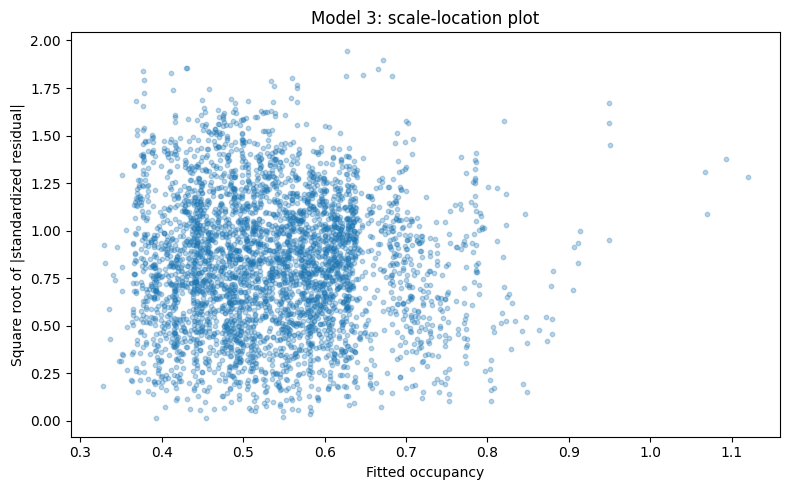

,Test,LM statistic,LM p-value,F statistic,F p-value
0,Breusch–Pagan (default Koenker version),207.230,3.374e-41,31.153,2.605e-42
1,White,394.973,4.755e-63,12.772,8.185e-67


In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(fitted, np.sqrt(np.abs(standardized)), s=10, alpha=0.3)
ax.set_xlabel("Fitted occupancy")
ax.set_ylabel("Square root of |standardized residual|")
ax.set_title("Model 3: scale-location plot")
fig.tight_layout()
plt.show()

bp = het_breuschpagan(residuals, X3)
white = het_white(residuals, X3)
variance_tests = pd.DataFrame({
    "Test": ["Breusch–Pagan (default Koenker version)", "White"],
    "LM statistic": [bp[0], white[0]],
    "LM p-value": [bp[1], white[1]],
    "F statistic": [bp[2], white[2]],
    "F p-value": [bp[3], white[3]]
})
variance_tests.style.format({
    "LM statistic": "{:.3f}", "LM p-value": "{:.3e}",
    "F statistic": "{:.3f}", "F p-value": "{:.3e}"
})

Both tests reject constant variance: the Breusch–Pagan LM p-value is **3.37 × 10⁻⁴¹**, and White's is **4.75 × 10⁻⁶³**. Conventional standard errors, intervals, and tests therefore need caution; changing the covariance estimate does not change the OLS coefficients or fix a misspecified mean.

The uncertainty comparison uses **HC1** heteroskedasticity-consistent standard errors. It still treats different spaces as independent.

In [10]:
model3_hc1 = sm.OLS(y, X3).fit(cov_type="HC1")

robust_comparison = pd.DataFrame({
    "Coefficient": model3.params,
    "OLS SE": model3.bse,
    "HC1 SE": model3_hc1.bse,
    "OLS p-value": model3.pvalues,
    "HC1 p-value": model3_hc1.pvalues,
    "HC1 95% lower": model3_hc1.conf_int()[0],
    "HC1 95% upper": model3_hc1.conf_int()[1]
})
print("Largest coefficient change:", (model3.params - model3_hc1.params).abs().max())
robust_comparison.style.format({
    "Coefficient": "{:.6g}", "OLS SE": "{:.6g}", "HC1 SE": "{:.6g}",
    "OLS p-value": "{:.3e}", "HC1 p-value": "{:.3e}",
    "HC1 95% lower": "{:.6g}", "HC1 95% upper": "{:.6g}"
})

Largest coefficient change: 0.0


,Coefficient,OLS SE,HC1 SE,OLS p-value,HC1 p-value,HC1 95% lower,HC1 95% upper
const,0.456337,0.0157939,0.0171155,6.470e-167,1.291e-156,0.422792,0.489883
price_midpoint,0.0556328,0.00236136,0.00232226,4.731e-115,7.931e-127,0.0510813,0.0601844
time_limit_hours,0.00487929,0.00294796,0.00313717,9.797e-02,1.199e-01,-0.00126946,0.011028
population_density,4.57052e-06,2.21771e-07,2.37074e-07,8.803e-90,8.077e-83,4.10586e-06,5.03518e-06
nearby_restaurant_retail_count,-0.000321282,2.29852e-05,2.4298e-05,2.189e-43,6.502e-40,-0.000368905,-0.000273659
drive_alone_share,-0.198101,0.0208314,0.0211007,3.195e-21,6.095e-21,-0.239458,-0.156744
transit_share,0.0196471,0.0468362,0.0452127,6.749e-01,6.639e-01,-0.0689682,0.108262
RateType_TOD,0.0330042,0.00731608,0.00857071,6.631e-06,1.177e-04,0.0162059,0.0498025


The price estimate stays **0.05563**; its HC1 standard error is **0.002322**, versus **0.002361** conventionally, with an HC1 95% interval of **0.05108 to 0.06018**. Its positive association remains statistically clear under this correction, while time limit and transit share remain uncertain. HC1 uses statsmodels' default normal-reference inference here; it does not account for within-tract dependence.

### Log-density sensitivity

The following sensitivity comparison assesses whether a log transformation of population density improves functional form. HC1 uncertainty permits comparison with the primary specification.


**Alternative specification**

A natural-log transformation can reduce the skewness of a positive explanatory variable and allow a nonlinear relationship in its original units. The alternative replaces population density only, keeping the same observations, outcome and other six predictors; this is a sensitivity check rather than a new primary model.

In [12]:
log_data = data.copy()
assert log_data["population_density"].gt(0).all()
log_data["log_population_density"] = np.log(log_data["population_density"])
log_predictors = ["log_population_density" if v == "population_density" else v for v in predictors]
log_X = sm.add_constant(log_data[log_predictors])
log_model = sm.OLS(y, log_X).fit()
log_hc1 = sm.OLS(y, log_X).fit(cov_type="HC1")
log_reset = linear_reset(log_model, power=2, test_type="fitted", use_f=True)
log_comparison = pd.DataFrame({
    "Specification": ["Original density (primary)", "Log density (robustness)"],
    "N": [int(model3.nobs), int(log_model.nobs)],
    "Price coefficient": [model3.params["price_midpoint"], log_model.params["price_midpoint"]],
    "HC1 price SE": [model3_hc1.bse["price_midpoint"], log_hc1.bse["price_midpoint"]],
    "Adjusted R2": [model3.rsquared_adj, log_model.rsquared_adj],
    "AIC": [model3.aic, log_model.aic],
    "BIC": [model3.bic, log_model.bic],
    "RESET p-value": [float(reset.pvalue), float(log_reset.pvalue)]
})
log_comparison.style.format({"Price coefficient": "{:.6f}", "HC1 price SE": "{:.6f}",
    "Adjusted R2": "{:.5f}", "AIC": "{:.2f}", "BIC": "{:.2f}", "RESET p-value": "{:.3e}"})

,Specification,N,Price coefficient,HC1 price SE,Adjusted R2,AIC,BIC,RESET p-value
0,Original density (primary),4016,0.055633,0.002322,0.27235,-3070.71,-3020.33,5.605e-28
1,Log density (robustness),4016,0.055160,0.002309,0.27325,-3075.69,-3025.30,1.416e-19


Price changes only from **0.05563 to 0.05516**, or **5.56 to 5.52 percentage points per dollar**. Adjusted R² improves slightly from **0.27235 to 0.27325** and AIC falls to **−3,075.69**, but RESET still rejects (**p ≈ 1.42 × 10⁻¹⁹**). This small transformation preserves the price conclusion without resolving the functional-form problem.

## 4(c) Residual Normality


### Check residual normality

The normality assessment compares internally standardized residuals with normal quantiles and uses the Jarque–Bera test, whose null is normal residuals. The histogram is shown in the preceding section rather than repeated here. With a large sample, a test can detect small departures, and failing to reject is not proof of normality.

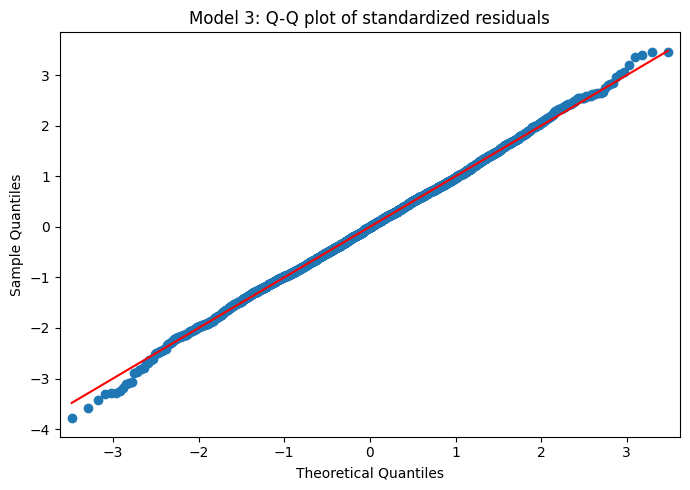

JB statistic    3.835976
P-value         0.146902
Skewness        0.031068
Kurtosis        3.138070
dtype: float64

In [8]:
fig, ax = plt.subplots(figsize=(7, 5))
sm.qqplot(standardized, line="s", ax=ax)
ax.set_title("Model 3: Q-Q plot of standardized residuals")
fig.tight_layout()
plt.show()

jb = jarque_bera(residuals)
normality = pd.Series(jb, index=["JB statistic", "P-value", "Skewness", "Kurtosis"])
normality

Jarque–Bera is **3.836**, with **p = 0.1469**, so residual normality is not rejected at 5%. Skewness is close to zero and kurtosis is about 3.138; the Q-Q plot is close to the reference line in the center with some tail departures. This result says nothing by itself about constant variance, independence, or the correctness of the conditional mean.

## 4(d) Outliers and Influence


### Screen for influential observations

Cook's distance, leverage, and externally studentized residuals are linked back to the unchanged source-row index and parking identifiers. The screening criteria use Cook's **4/n** rule, the **2p/n** leverage rule, and **|studentized residual| > 2**, where p includes the intercept. These are screening rules, not evidence that a record is incorrect.

In [13]:
diagnostics = parking.loc[data.index, ["SpaceID", "BlockFace", "GEOID"]].copy()
diagnostics["cooks_d"] = influence.cooks_distance[0]
diagnostics["hat_diag"] = influence.hat_matrix_diag
diagnostics["studentized_residual"] = influence.resid_studentized_external

n = int(model3.nobs)
p = len(model3.params)
cook_cutoff = 4 / n
leverage_cutoff = 2 * p / n

diagnostics["cook_flag"] = diagnostics["cooks_d"] > cook_cutoff
diagnostics["leverage_flag"] = diagnostics["hat_diag"] > leverage_cutoff
diagnostics["residual_flag"] = diagnostics["studentized_residual"].abs() > 2

print("Rows align with the model:", diagnostics.index.equals(model3.model.data.row_labels))
print("n, p (including intercept):", n, p)
print("Cook cutoff:", cook_cutoff)
print("Leverage cutoff:", leverage_cutoff)
diagnostics[["cook_flag", "leverage_flag", "residual_flag"]].sum()

Rows align with the model: True
n, p (including intercept): 4016 8
Cook cutoff: 0.00099601593625498
Leverage cutoff: 0.00398406374501992


cook_flag        249
leverage_flag    136
residual_flag    189
dtype: int64

In [14]:
diagnostics.nlargest(10, "cooks_d")[[
    "SpaceID", "BlockFace", "GEOID", "cooks_d", "hat_diag",
    "studentized_residual", "cook_flag", "leverage_flag", "residual_flag"
]]

,SpaceID,BlockFace,GEOID,cooks_d,hat_diag,studentized_residual,cook_flag,leverage_flag,residual_flag
1487,CB3699,601 MAIN ST,06037207308,0.012662,0.009496,-3.254396,True,True,True
1464,CB3647,501 SPRING ST,06037207304,0.011832,0.025590,-1.899096,True,True,False
1466,CB3648B,501 SPRING ST,06037207304,0.009983,0.026675,-1.707438,True,True,False
1468,CB3651,601 SPRING ST,06037207304,0.009970,0.028511,-1.648906,True,True,False
1952,CB4486,700 BROADWAY,06037207303,0.007409,0.009203,2.527712,True,True,True
463,CB1616,900 FIGUEROA ST,06037207901,0.006182,0.006276,-2.800825,True,True,True
2739,HO482,6301 YUCCA ST,06037190201,0.005751,0.003557,-3.595343,True,False,True
464,CB1617,900 FIGUEROA ST,06037207901,0.004745,0.006265,-2.455299,True,True,True
1465,CB3648,501 SPRING ST,06037207304,0.004721,0.026527,-1.177304,True,True,False
1139,CB2930,600 HILL ST,06037207305,0.004482,0.005088,2.649829,True,True,True


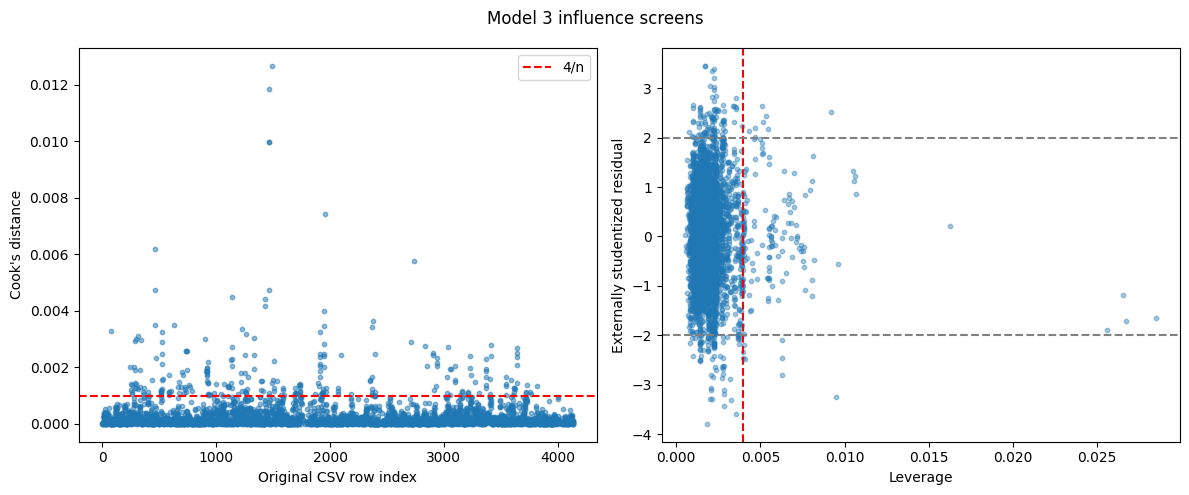

In [15]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
axes[0].scatter(diagnostics.index, diagnostics["cooks_d"], s=10, alpha=0.5)
axes[0].axhline(cook_cutoff, color="red", linestyle="--", label="4/n")
axes[0].set_xlabel("Original CSV row index")
axes[0].set_ylabel("Cook's distance")
axes[0].legend()
axes[1].scatter(diagnostics["hat_diag"], diagnostics["studentized_residual"],
                s=10, alpha=0.4)
axes[1].axvline(leverage_cutoff, color="red", linestyle="--")
axes[1].axhline(2, color="grey", linestyle="--")
axes[1].axhline(-2, color="grey", linestyle="--")
axes[1].set_xlabel("Leverage")
axes[1].set_ylabel("Externally studentized residual")
fig.suptitle("Model 3 influence screens")
fig.tight_layout()
plt.show()

The screens flag **249/4,016** spaces by Cook's distance, **136/4,016** by leverage, and **189/4,016** by studentized residuals; these groups overlap. The highest Cook's distance is about **0.01266** for **CB3699, 601 MAIN ST**. Several high-leverage spaces share small downtown tracts, so identifiers and context are inspected rather than records being deleted automatically.

<a id="model3-dfbetas"></a>

### Coefficient-specific influence: DFBETAS

DFBETAS measures each observation’s standardized contribution to each fitted coefficient: the full-fit coefficient minus its leave-one-observation-out counterpart, standardized using the deletion-based error scale and full-design covariance factor. Columns include the intercept and follow `model3.params.index`. The cutoff **2/√n is a screening rule**, not proof of an erroneous or bad observation. This diagnostic does not change Model 3 or remove any observations.


In [16]:
# Use the fitted model's observation order, retaining original CSV row labels.
dfbetas_model_rows = pd.Index(model3.model.data.row_labels)
dfbetas_values = model3.get_influence().dfbetas
assert dfbetas_values.shape == (int(model3.nobs), len(model3.params))
assert dfbetas_model_rows.is_unique
assert dfbetas_model_rows.equals(X3.index)
assert dfbetas_model_rows.equals(y.index)
assert dfbetas_model_rows.equals(diagnostics.index)
np.testing.assert_allclose(model3.model.exog, X3.loc[dfbetas_model_rows].to_numpy())
np.testing.assert_allclose(model3.model.endog, y.loc[dfbetas_model_rows].to_numpy())
assert np.isfinite(dfbetas_values).all()

dfbetas = pd.DataFrame(
    dfbetas_values, index=dfbetas_model_rows, columns=model3.params.index
)
dfbetas.index.name = "source_row"
assert dfbetas.columns.equals(model3.params.index)
dfbetas_cutoff = 2 / np.sqrt(int(model3.nobs))
print(f"DFBETAS rows verified against model observations: {len(dfbetas):,}")
print(f"Screening rule only: |DFBETAS| > 2/sqrt(n) = {dfbetas_cutoff:.5f}")

# Report magnitude, signed value, and the matching observation for each coefficient.
dfbetas_peak_rows = dfbetas.abs().idxmax()
dfbetas_summary = pd.DataFrame({
    "Max absolute DFBETAS": dfbetas.abs().max(),
    "Signed DFBETAS at maximum": [dfbetas.loc[row, name] for name, row in dfbetas_peak_rows.items()],
    "Source row at maximum": dfbetas_peak_rows,
    "SpaceID at maximum": [parking.loc[row, "SpaceID"] for row in dfbetas_peak_rows],
    "Count above screening rule": dfbetas.abs().gt(dfbetas_cutoff).sum()
})
dfbetas_summary.index.name = "Coefficient"
dfbetas_summary.style.format({
    "Max absolute DFBETAS": "{:.5f}",
    "Signed DFBETAS at maximum": "{:.5f}"
})


DFBETAS rows verified against model observations: 4,016
Screening rule only: |DFBETAS| > 2/sqrt(n) = 0.03156


,Max absolute DFBETAS,Signed DFBETAS at maximum,Source row at maximum,SpaceID at maximum,Count above screening rule
Coefficient,,,,,
const,0.12879,-0.12879,3411,SV202,254
price_midpoint,0.15840,0.15840,1487,CB3699,220
time_limit_hours,0.13531,0.13531,2739,HO482,330
population_density,0.27746,-0.27746,1464,CB3647,204
nearby_restaurant_retail_count,0.25331,-0.25331,1487,CB3699,184
drive_alone_share,0.10192,-0.10192,1946,CB4462,253
transit_share,0.11101,-0.11101,2739,HO482,197
RateType_TOD,0.12667,-0.12667,1946,CB4462,346


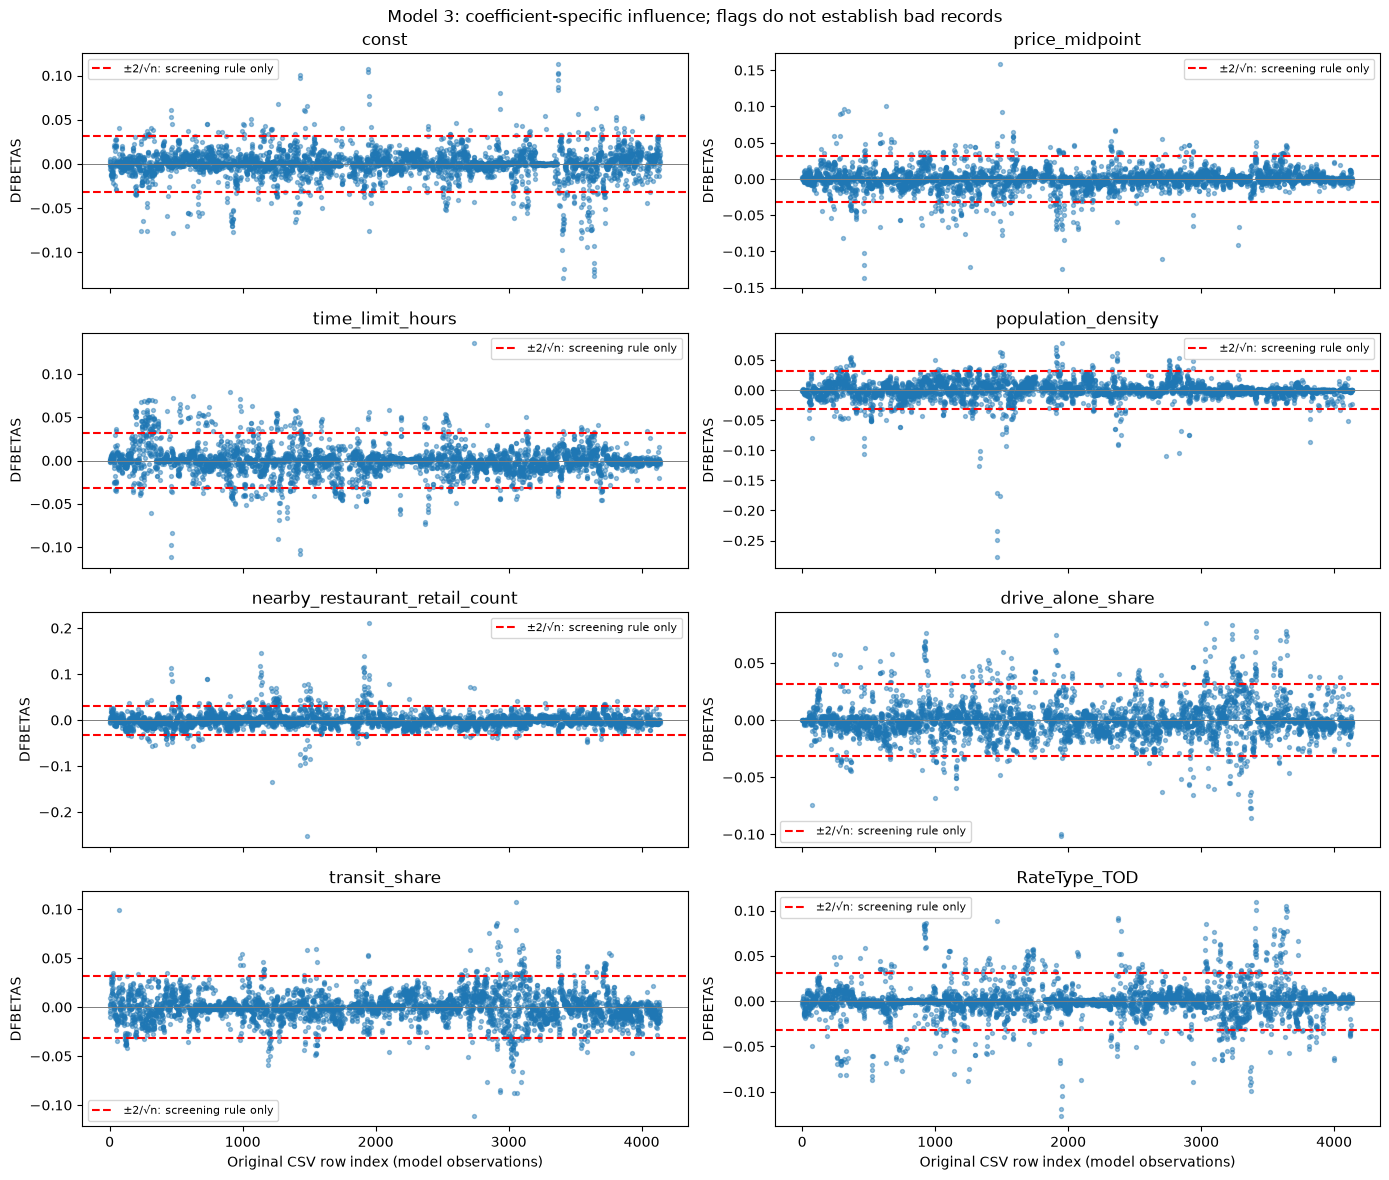

In [17]:
fig, axes = plt.subplots(4, 2, figsize=(14, 12), sharex=True)
for ax, name in zip(axes.flat, dfbetas.columns):
    ax.scatter(dfbetas.index, dfbetas[name], s=8, alpha=0.45)
    ax.axhline(0, color="grey", linewidth=0.7)
    ax.axhline(dfbetas_cutoff, color="red", linestyle="--",
               label="±2/√n: screening rule only")
    ax.axhline(-dfbetas_cutoff, color="red", linestyle="--")
    ax.set_title(name)
    ax.set_ylabel("DFBETAS")
    ax.legend(fontsize=8)
for ax in axes[-1]:
    ax.set_xlabel("Original CSV row index (model observations)")
fig.suptitle("Model 3: coefficient-specific influence; flags do not establish bad records")
fig.tight_layout()
plt.show()


In [18]:
from IPython.display import display, Markdown

dfbetas_most_affected = dfbetas_summary["Max absolute DFBETAS"].idxmax()
dfbetas_any_flags = int(dfbetas.abs().gt(dfbetas_cutoff).any(axis=1).sum())
dfbetas_price_peak = dfbetas_summary.loc["price_midpoint"]
display(Markdown(
    f"**DFBETAS interpretation.** {dfbetas_any_flags:,} of {len(dfbetas):,} spaces "
    f"exceed the ±{dfbetas_cutoff:.5f} screening rule for at least one coefficient. "
    f"The largest absolute DFBETAS is "
    f"{dfbetas_summary.loc[dfbetas_most_affected, 'Max absolute DFBETAS']:.5f} "
    f"for **{dfbetas_most_affected}**. For price, the largest absolute value is "
    f"{dfbetas_price_peak['Max absolute DFBETAS']:.5f}, at SpaceID "
    f"**{dfbetas_price_peak['SpaceID at maximum']}**. "
    "The table and panels show which coefficients are most sensitive to individual observations; "
    "the signed values indicate the direction of the full-fit minus deleted-fit change. "
    "Flag counts overlap across coefficients and a low screening threshold can flag many ordinary "
    "observations. These results motivate contextual review, not automatic deletion, and do not "
    "resolve heteroskedasticity, spatial dependence, or endogeneity. "
    "All observations and the original Model 3 remain unchanged."
))
# Guard against unintended changes to the primary model or its sample.
assert int(model3.nobs) == len(dfbetas_model_rows)
np.testing.assert_allclose(model3.params.to_numpy(), np.linalg.lstsq(X3, y, rcond=None)[0])


**DFBETAS interpretation.** 927 of 4,016 spaces exceed the ±0.03156 screening rule for at least one coefficient. The largest absolute DFBETAS is 0.27746 for **population_density**. For price, the largest absolute value is 0.15840, at SpaceID **CB3699**. The table and panels show which coefficients are most sensitive to individual observations; the signed values indicate the direction of the full-fit minus deleted-fit change. Flag counts overlap across coefficients and a low screening threshold can flag many ordinary observations. These results motivate contextual review, not automatic deletion, and do not resolve heteroskedasticity, spatial dependence, or endogeneity. All observations and the original Model 3 remain unchanged.

### Check sensitivity to Cook's-distance flags

The sensitivity analysis refits the same seven-variable specification after excluding only spaces above 4/n for Cook's distance. This is a sensitivity comparison, not a new cleaning rule, and the 4,016-space fit remains primary. Fit statistics across different samples do not establish that the screened sample is a better model.

In [16]:
keep = diagnostics["cooks_d"] <= cook_cutoff
model3_sensitivity = sm.OLS(y.loc[keep], X3.loc[keep]).fit()

sensitivity = pd.DataFrame({
    "Sample": ["Full sample (primary)", "Cook <= 4/n (sensitivity)"],
    "N": [int(model3.nobs), int(model3_sensitivity.nobs)],
    "Price coefficient": [model3.params["price_midpoint"],
                          model3_sensitivity.params["price_midpoint"]],
    "Price p-value": [model3.pvalues["price_midpoint"],
                      model3_sensitivity.pvalues["price_midpoint"]],
    "Adjusted R2": [model3.rsquared_adj, model3_sensitivity.rsquared_adj]
})
sensitivity.style.format({
    "Price coefficient": "{:.6f}", "Price p-value": "{:.3e}", "Adjusted R2": "{:.5f}"
})

,Sample,N,Price coefficient,Price p-value,Adjusted R2
0,Full sample (primary),4016,0.055633,4.731e-115,0.27235
1,Cook <= 4/n (sensitivity),3767,0.054769,1.393e-133,0.36202


In [17]:
sensitivity_coefficients = pd.DataFrame({
    "Full-sample coefficient": model3.params,
    "Sensitivity coefficient": model3_sensitivity.params,
    "Sensitivity p-value": model3_sensitivity.pvalues
})
sensitivity_coefficients.style.format({
    "Full-sample coefficient": "{:.6g}", "Sensitivity coefficient": "{:.6g}",
    "Sensitivity p-value": "{:.3e}"
})

,Full-sample coefficient,Sensitivity coefficient,Sensitivity p-value
const,0.456337,0.48932,2.835e-222
price_midpoint,0.0556328,0.054769,1.393e-133
time_limit_hours,0.00487929,0.0027943,2.905e-01
population_density,4.57052e-06,5.30055e-06,4.065e-132
nearby_restaurant_retail_count,-0.000321282,-0.000390916,2.212e-72
drive_alone_share,-0.198101,-0.247766,2.910e-39
transit_share,0.0196471,-0.03217,4.334e-01
RateType_TOD,0.0330042,0.0339612,7.397e-07


Excluding 249 flagged spaces leaves **3,767** observations. Price changes from **0.05563 to 0.05477** (about **5.56 to 5.48 percentage points per $1**) and remains positive with a small conventional p-value. The registration-count and drive-alone coefficients become more negative, while the uncertain transit estimate changes sign, so not every coefficient is equally stable.

Adjusted R² rises from 0.27235 to 0.36202, but the sample was selected using residual influence, which can mechanically improve fit. These p-values remain conventional and do not resolve the heteroskedasticity or dependence concerns. No observations are removed from the source file or the primary model.

## 4(e) Bootstrap


### Bootstrap the preferred specification

The bootstrap samples rows with replacement, fits the same model, and records its coefficients for **1,000 replications**, with seed **90095**. All coefficient estimates are summarized, followed by a focus on price. This holds the selected specification fixed rather than rerunning variable selection in every draw.

In [18]:
np.random.seed(90095)
n_boot = 1000
bootstrap_coefficients = []

for i in range(n_boot):
    sample = data.sample(n=len(data), replace=True)
    X_boot = sm.add_constant(sample[predictors])
    bootstrap_model = sm.OLS(sample["occupancy_rate"], X_boot).fit()
    bootstrap_coefficients.append(bootstrap_model.params)

bootstrap = pd.DataFrame(bootstrap_coefficients)
print("Bootstrap replications:", len(bootstrap))
bootstrap_summary = pd.DataFrame({
    "Original OLS": model3.params,
    "Bootstrap mean": bootstrap.mean(),
    "Bootstrap SE": bootstrap.std(ddof=1),
    "Percentile 95% lower": bootstrap.quantile(0.025),
    "Percentile 95% upper": bootstrap.quantile(0.975)
})
bootstrap_summary.style.format("{:.6g}")

Bootstrap replications: 1000


,Original OLS,Bootstrap mean,Bootstrap SE,Percentile 95% lower,Percentile 95% upper
const,0.456337,0.456724,0.017315,0.422518,0.49125
price_midpoint,0.0556328,0.0554847,0.00237433,0.0509139,0.0601064
time_limit_hours,0.00487929,0.0049741,0.00314588,-0.000987099,0.0110299
population_density,4.57052e-06,4.58343e-06,2.35249e-07,4.11908e-06,5.07294e-06
nearby_restaurant_retail_count,-0.000321282,-0.000321162,2.41982e-05,-0.000371127,-0.000273167
drive_alone_share,-0.198101,-0.199397,0.0213658,-0.244678,-0.157657
transit_share,0.0196471,0.0202927,0.0445782,-0.0653932,0.102353
RateType_TOD,0.0330042,0.0327779,0.0086254,0.0160399,0.0487384


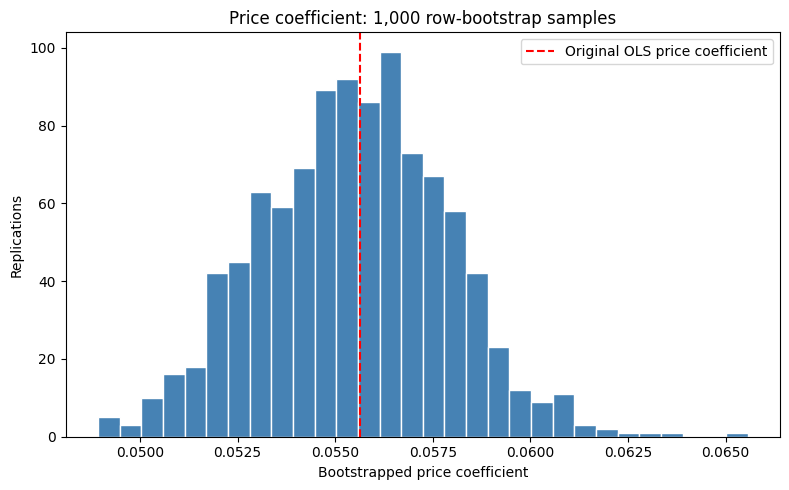

In [19]:
plt.figure(figsize=(8, 5))
plt.hist(bootstrap["price_midpoint"], bins=30, color="steelblue", edgecolor="white")
plt.axvline(model3.params["price_midpoint"], color="red", linestyle="--",
            label="Original OLS price coefficient")
plt.xlabel("Bootstrapped price coefficient")
plt.ylabel("Replications")
plt.title("Price coefficient: 1,000 row-bootstrap samples")
plt.legend()
plt.tight_layout()
plt.show()

The original price coefficient is **0.05563**; the bootstrap mean is **0.05548**, with bootstrap standard error **0.002374** and percentile interval **[0.05091, 0.06011]**. In percentage-point units per dollar, the interval is approximately **[5.09, 6.01]**, supporting stability of the positive association under this resampling scheme.

Ordinary row bootstrap treats spaces as independent even though the sample spans only 45 tracts and several predictors are shared within tracts. Tract-clustered uncertainty is not estimated here, so within-tract dependence remains an unresolved limitation. The bootstrap does not fix endogeneity, mixed data vintages, or functional-form problems.

## 4(f) Cross-Validation


### Five-fold held-out prediction accuracy

The first table reports reference RMSE values; the subsequent calculation estimates held-out accuracy using shuffled five-fold splits with seed 10. Each fixed model is fitted on training rows only, and each observation receives exactly one held-out prediction. The results report fold RMSE, its mean and standard deviation, and pooled out-of-fold RMSE. This evaluates the fixed specifications, not the earlier variable-selection process; spatial overlap also limits interpretation as new-neighborhood accuracy.


In [20]:
cv_reference = pd.DataFrame({
    "Model": ["Model 1", "Model 2", "Model 3"],
    "Mean held-out RMSE (Notebook 06)": [0.17756, 0.16821, 0.16532]
})
cv_reference

,Model,Mean held-out RMSE (Notebook 06)
0,Model 1,0.17756
1,Model 2,0.16821
2,Model 3,0.16532


In [24]:
# Actual held-out predictions for the unchanged specifications, using common folds.
from sklearn.model_selection import KFold
from sklearn.metrics import mean_squared_error

cv_folds = list(KFold(n_splits=5, shuffle=True, random_state=10).split(data))
cv_rows = []
cv_oof = pd.DataFrame(index=data.index)
cv_full_params_before = model3.params.copy()
for cv_name, cv_design in [("Model 1", X1), ("Model 2", X2), ("Model 3", X3)]:
    assert cv_design.index.equals(y.index)
    cv_predictions = pd.Series(np.nan, index=data.index, dtype=float)
    cv_seen = np.zeros(len(data), dtype=int)
    for cv_fold, (cv_train, cv_test) in enumerate(cv_folds, start=1):
        assert not np.intersect1d(cv_train, cv_test).size
        cv_fit = sm.OLS(y.iloc[cv_train], cv_design.iloc[cv_train]).fit()
        cv_pred = cv_fit.predict(cv_design.iloc[cv_test])
        cv_predictions.iloc[cv_test] = cv_pred.to_numpy()
        cv_seen[cv_test] += 1
        cv_rows.append({"Model": cv_name, "Fold": cv_fold,
                        "Training N": len(cv_train), "Held-out N": len(cv_test),
                        "Held-out RMSE": np.sqrt(mean_squared_error(y.iloc[cv_test], cv_pred))})
    assert (cv_seen == 1).all() and cv_predictions.notna().all()
    cv_oof[cv_name] = cv_predictions
cv_fold_results = pd.DataFrame(cv_rows)
cv_summary_actual = cv_fold_results.groupby("Model")["Held-out RMSE"].agg(
    **{"Mean fold RMSE": "mean", "Fold RMSE SD": "std"})
cv_summary_actual["Pooled out-of-fold RMSE"] = [
    np.sqrt(mean_squared_error(y, cv_oof[name])) for name in cv_summary_actual.index]
# Cross-validation uses local fits; the primary Model 3 is untouched.
pd.testing.assert_series_equal(model3.params, cv_full_params_before)
assert int(model3.nobs) == len(data)
display(cv_fold_results.round(5))
display(cv_summary_actual.round(5))
print("Verified five held-out folds per model; each observation predicted once using training-only fits.")
print(f"Model 3 mean fold RMSE: {cv_summary_actual.loc['Model 3', 'Mean fold RMSE']:.5f} "
      f"({100 * cv_summary_actual.loc['Model 3', 'Mean fold RMSE']:.2f} occupancy percentage points).")


,Model,Fold,Training N,Held-out N,Held-out RMSE
0,Model 1,1,3212,804,0.17539
1,Model 1,2,3213,803,0.17974
2,Model 1,3,3213,803,0.17911
3,Model 1,4,3213,803,0.17685
4,Model 1,5,3213,803,0.17673
5,Model 2,1,3212,804,0.16599
6,Model 2,2,3213,803,0.17100
7,Model 2,3,3213,803,0.17081
8,Model 2,4,3213,803,0.16538
9,Model 2,5,3213,803,0.16787


,Mean fold RMSE,Fold RMSE SD,Pooled out-of-fold RMSE
Model,,,
Model 1,0.17756,0.00181,0.17757
Model 2,0.16821,0.00263,0.16822
Model 3,0.16532,0.00173,0.16532


Verified five held-out folds per model; each observation predicted once using training-only fits.
Model 3 mean fold RMSE: 0.16532 (16.53 occupancy percentage points).


Model 3 has the lowest mean error, about **16.53 percentage points in root-mean-square terms**. Random-fold validation can place nearby spaces and the same tract in training and test data, and this sample was also used for variable selection. It is a comparison of the fixed models for held-out spaces, not proof of performance in new neighborhoods or independent validation of the whole selection process.

## 4(g) OLS Violations and Implications


### Check coverage and feasible sample sensitivities

The primary outcome uses intervals at most 24 hours and at least 25 transaction-active days. Recorded coverage is inspected first; these checks do not change the sample. The existing data then support a stricter 28-day sample and an income-missingness comparison, keeping the original sample primary.

In [21]:
print("Transaction-active days in the primary sample:")
print(parking.loc[data.index, "active_days"].value_counts().sort_index())

valid_month_fraction = parking.loc[data.index, "total_minutes"] / (31 * 24 * 60)
valid_month_fraction.describe()

Transaction-active days in the primary sample:
active_days
25     356
26    2032
27      19
28      45
29      89
30     184
31    1291
Name: count, dtype: int64


count    4016.000000
mean        0.822536
std         0.117815
min         0.315420
25%         0.741356
50%         0.775555
75%         0.966179
max         0.999898
Name: total_minutes, dtype: float64

Retained valid minutes average **82.25%** of August, with a median of **77.56%** and a minimum of **31.54%**. Active days do not necessarily mean fully monitored days, and the raw sensor records showed Sunday-reporting differences. A 28-day restriction is feasible using the saved active-day count; expanding to 20 days or changing interval cutoffs requires rebuilding the sensor outcomes.

In [22]:
days_data = data.loc[parking.loc[data.index, "active_days"].ge(28)].copy()
days_model = sm.OLS(days_data["occupancy_rate"], sm.add_constant(days_data[predictors])).fit(cov_type="HC1")
income_data = parking[["occupancy_rate", *predictors]].dropna()
income_model = sm.OLS(income_data["occupancy_rate"], sm.add_constant(income_data[predictors])).fit(cov_type="HC1")

sample_checks = pd.DataFrame([
    ["Primary common sample", model3_hc1],
    ["At least 28 active days", days_model],
    ["Retain missing-income spaces", income_model]
], columns=["Sample", "Fit"])
sample_summary = pd.DataFrame({
    "Sample": sample_checks["Sample"],
    "N": [int(m.nobs) for m in sample_checks["Fit"]],
    "Price coefficient": [m.params["price_midpoint"] for m in sample_checks["Fit"]],
    "HC1 95% lower": [m.conf_int().loc["price_midpoint", 0] for m in sample_checks["Fit"]],
    "HC1 95% upper": [m.conf_int().loc["price_midpoint", 1] for m in sample_checks["Fit"]],
    "Adjusted R2": [m.rsquared_adj for m in sample_checks["Fit"]]
})
sample_summary.round(6)

,Sample,N,Price coefficient,HC1 95% lower,HC1 95% upper,Adjusted R2
0,Primary common sample,4016,0.055633,0.051081,0.060184,0.272354
1,At least 28 active days,1609,0.049628,0.041057,0.058199,0.204005
2,Retain missing-income spaces,4060,0.057162,0.052560,0.061763,0.270828


The 28-day sample contains **1,609** spaces and gives a price coefficient of **0.04963**, versus **0.05563** in the primary sample. Restoring the 44 missing-income spaces gives **4,060** observations and a coefficient of **0.05716**; income is not a regressor, so this needs no imputation. Both comparisons retain a positive association, but the 28-day restriction changes sample composition and does not test a different interval definition.

### Limitations of sensor-threshold comparisons

Alternative 12-, 24-, and 48-hour interval cutoffs and 20-, 25-, and 28-active-day restrictions would require reconstruction from the August 2025 sensor transactions (3,707,820 records). Such comparisons have not been estimated here. Reconstruction would require parsing local timestamps, sorting within SpaceID, calculating next-record intervals before excluding UNKNOWN states, and aggregating occupied and valid minutes separately for each cutoff. Raw active days would be counted before applying day restrictions.

Expanded samples would require verified meter and neighborhood-predictor linkage because newly eligible spaces may lack predictors available for the primary sample. Comparisons should distinguish changes in measured occupancy for a common set of spaces from changes in sample composition. The available 28-day comparison changes the retained sample but does not evaluate a different interval definition.


### Diagnostic findings and implications

The summary below combines the tests and robustness checks, keeping screening rules distinct from decisions to change the data. A normality test that does not reject does not offset the variance and functional-form concerns. The price association is stable in the completed sensitivity checks, but its interpretation remains conditional and noncausal.

In [27]:
diagnostic_summary = pd.DataFrame([
    ["Residual plots", "Uneven spread; tract bands", "Inspect variance and mean specification", "Yes"],
    ["Jarque–Bera", f"p = {jb[1]:.3g}", "Do not reject normality at 5%", "Review with other assumptions"],
    ["Breusch–Pagan LM", f"p = {bp[1]:.3e}", "Reject constant variance", "Yes; HC1 comparison shown"],
    ["White LM", f"p = {white[1]:.3e}", "Reject constant variance", "Yes"],
    ["RESET", f"p = {float(reset.pvalue):.3e}", "Possible functional-form problem", "Yes"],
    ["Influence", f"{diagnostics['cook_flag'].sum()} Cook flags / {n}", "Screening flags, not confirmed errors", "Review identified spaces"],
    ["DFBETAS", f"Max |DFBETAS| = {dfbetas.abs().to_numpy().max():.5f}; {dfbetas_any_flags} spaces flagged", "Coefficient-specific screening only", "No automatic deletion"],
    ["Cook sensitivity", f"Price = {model3_sensitivity.params['price_midpoint']:.5f}", "Positive price association remains", "Keep full sample primary"],
    ["Row bootstrap", f"{len(bootstrap):,} draws; price CI [{bootstrap_summary.loc['price_midpoint', 'Percentile 95% lower']:.5f}, {bootstrap_summary.loc['price_midpoint', 'Percentile 95% upper']:.5f}]", "Positive interval; independence assumed", "Dependence remains unresolved"],
    ["Five-fold CV", f"Model 3 mean RMSE {cv_summary_actual.loc['Model 3', 'Mean fold RMSE']:.5f} (computed here)", "Best of the three fixed models", "New-neighborhood validity unresolved"],
    ["Log-density check", f"Price = {log_model.params['price_midpoint']:.5f}; RESET p = {float(log_reset.pvalue):.3e}", "Price stable; RESET still rejects", "Keep original Model 3 primary"],
    ["28 active days", f"N = {int(days_model.nobs)}; price = {days_model.params['price_midpoint']:.5f}", "Positive association in a stricter sample", "Does not change interval definition"],
    ["Income-missingness sensitivity", f"N = {int(income_model.nobs)}; price = {income_model.params['price_midpoint']:.5f}", "Retaining missing-income spaces preserves sign", "Keep original common sample primary"],
    ["Other sensor thresholds", "12/48-hour and 20-day alternatives not rebuilt", "Coverage rules may affect Y and sample", "Approval needed for raw-data rebuild"]
], columns=["Diagnostic", "Result", "Interpretation", "Further investigation"])
diagnostic_summary

,Diagnostic,Result,Interpretation,Further investigation
0,Residual plots,Uneven spread; tract bands,Inspect variance and mean specification,Yes
1,Jarque–Bera,p = 0.147,Do not reject normality at 5%,Review with other assumptions
2,Breusch–Pagan LM,p = 3.374e-41,Reject constant variance,Yes; HC1 comparison shown
3,White LM,p = 4.755e-63,Reject constant variance,Yes
4,RESET,p = 5.605e-28,Possible functional-form problem,Yes
5,Influence,249 Cook flags / 4016,"Screening flags, not confirmed errors",Review identified spaces
6,DFBETAS,Max |DFBETAS| = 0.27746; 927 spaces flagged,Coefficient-specific screening only,No automatic deletion
7,Cook sensitivity,Price = 0.05477,Positive price association remains,Keep full sample primary
8,Row bootstrap,"1,000 draws; price CI [0.05091, 0.06011]",Positive interval; independence assumed,Dependence remains unresolved
9,Five-fold CV,Model 3 mean RMSE 0.16532 (computed here),Best of the three fixed models,New-neighborhood validity unresolved


The full-sample price coefficient remains about **5.56 percentage points per $1**, and its row-bootstrap and HC1 intervals exclude zero. However, strong heteroskedasticity and RESET rejection mean the original linear model should not be described as fully validated. HC1 addresses heteroskedastic uncertainty under independence, not shared-tract dependence, functional form, or demand-responsive pricing.

The October 2026 price proxy and business registrations also differ in timing and meaning from August 2025 occupancy. The full 4,016-space Model 3 remains the primary result, with limitations reported before any final interpretation. No influential-observation screen becomes a permanent deletion rule, and the log-density alternative is only a robustness check; it does not remove the RESET concern.